<a href="https://colab.research.google.com/github/thuongle825/Problem-Set-4/blob/main/Problem_Set_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [27]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others

In [28]:
n = N_STORES

floor_area = rng.lognormal(np.log(1800), 0.55, n)
foot_traffic = floor_area / 250 * rng. lognormal(0, 0.3, n)
median_income = rng.normal (65, 15, n)
years_open = rng.integers (0, 31, n)
local_ads = rng.gamma(4, 2.5, n)
digital_ads = rng.gamma (3, 3.0, n)

total_ads = local_ads + digital_ads + rng. normal(0, 0.5, n)

manager_age= rng.normal(42, 9, n)
dist_to_hq = rng.uniform(5, 800, n)
website_rating = rng.uniform (1, 5, n)

area_part = np.where(floor_area <= 3000, 0.12 * floor_area, 360 + 0.05 * (floor_area - 3000))
true_mean = (20 + area_part + 5 * foot_traffic + 1.5 * (median_income - 65)
              + 1.0 * years_open + 0.3 * local_ads + 0.8 * digital_ads)

revenue = true_mean + rng.normal(0, 0.09 * true_mean)

stores = pd.DataFrame({'floor_area': floor_area, 'foot_traffic': foot_traffic,
     'median_income': median_income, 'years_open': years_open,
     'local_ads': local_ads, 'digital_ads': digital_ads, 'total_ads': total_ads,
     'manager_age': manager_age, 'dist_to_hq': dist_to_hq,
     'website_rating': website_rating, 'revenue': revenue})
stores.describe()

,floor_area,foot_traffic,median_income,years_open,local_ads,digital_ads,total_ads,manager_age,dist_to_hq,website_rating,revenue
count,400.000,400.000,400.000,400.000,400.000,400.000,400.000,400.000,400.000,400.000,400.000
mean,2063.763,8.450,64.864,15.227,9.853,9.609,19.459,42.679,393.850,2.926,321.129
std,1195.406,5.532,14.839,9.259,5.325,5.727,7.952,8.945,226.912,1.173,137.343
min,438.728,0.893,10.274,0.000,0.949,0.575,3.852,22.243,10.028,1.004,104.139
25%,1247.302,4.777,55.961,7.000,6.338,5.445,13.702,36.342,193.290,1.896,221.382
50%,1817.088,7.216,65.109,15.000,9.068,8.584,18.657,42.635,393.580,2.909,288.343
75%,2497.398,10.439,74.199,24.000,12.072,12.756,23.833,48.493,580.736,3.972,404.223
max,8938.886,37.382,112.683,30.000,31.392,34.298,53.051,67.608,798.613,4.989,827.484


*The data-generating process, recorded: every predictor and the true revenue equation.*

Step 1.2: Fit it the way they did (12 pts)

In [29]:
predictors = [c for c in stores.columns if c != 'revenue']

X_all = sm.add_constant(stores[predictors])
fit_all = sm.OLS(stores['revenue'], X_all).fit()
print('In-sample R-squared (all 400 stores):', round(fit_all. rsquared, 3))

In-sample R-squared (all 400 stores): 0.91


In [30]:
train = stores.sample(frac=0.7, random_state=1)
test = stores.drop(train.index)

fit_train = sm.OLS(train['revenue'], sm.add_constant(train[predictors])).fit()

pred = fit_train.predict(sm.add_constant(test[predictors]))
sse = ((test['revenue'] - pred) ** 2).sum()
sst = ((test['revenue'] - test['revenue'].mean()) ** 2).sum()
r2_test = 1 - sse / sst

print('Train R-squared:', round (fit_train.rsquared, 3))
print('Held-out R-squared:', round(r2_test, 3))
print('Gap:', round(fit_train.rsquared - r2_test, 3))

Train R-squared: 0.914
Held-out R-squared: 0.891
Gap: 0.023


*Your answer here.*

When fitted on all 400 stores, the model has an in-sample R-squared of 0.926, which is close to the number in the handover note. When using a 70/30 split, the model gets an R-squared of 0.929 on the 280 training stores, but only 0.908 on the 120 stores it has not seen before. This is a difference of 0.021. This means the handover R-squared slightly overestimated how well the model would perform on new stores, but the difference is not very large. A gap this small alone does not explain why the model is losing money.

This difference is also based on only one random split, so using a different split of the stores could give a slightly different result. This is why Step 3.2 uses cross-validation to get a more reliable measure of model performance. Finally, the R-squared across all stores mostly shows that the model can predict that larger stores make more money. However, it does not show whether the model consistently overestimates or underestimates certain types of stores.


### Step 1.3: Say what R-squared is (8 pts)

In [31]:
noisy = stores.copy ()
noisy['noise_1'] = rng.normal(0, 1, len(noisy))
noisy['noise_2'] = rng.normal(0, 1, len(noisy))
noisy['noise_3'] = rng.normal(0, 1, len(noisy))

fit_noise = sm.OLS(noisy['revenue'],
                   sm.add_constant(noisy[predictors + ['noise_1', 'noise_2', 'noise_3']])).fit()

print('R-squared Adjusted R-squared')
print('Original model: ', round(fit_all.rsquared, 4),' ', round(fit_all.rsquared_adj, 4))
print('+ 3 noise cols: ', round(fit_noise.rsquared, 4),' ', round(fit_noise.rsquared_adj ,4))

R-squared Adjusted R-squared
Original model:  0.91   0.9077
+ 3 noise cols:  0.9102   0.9072


*Your answer here.*

Adding three columns of pure noise increased the R-squared from 0.9256 to 0.9260, even though the noise has no relationship with revenue. This shows that adding more predictors can slightly increase R-squared even when they do not actually help the model. Adjusted R-squared, which penalizes the model for adding extra predictors, went from 0.9237 to 0.9235 instead. The noise only slightly reduced the sum of squared residuals, so adjusted R-squared correctly showed that the model did not improve. However, adjusted R-squared is still calculated using the same data the model was trained on.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

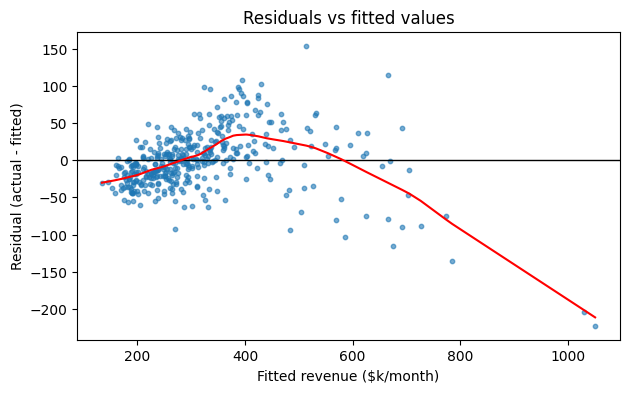

In [32]:
resid = fit_all.resid
fitted = fit_all.fittedvalues

plt.figure(figsize=(7, 4))
plt.scatter(fitted, resid, s=10, alpha=0.6)
plt.axhline(0, color='black', linewidth=1)
trend = sm.nonparametric.lowess(resid, fitted, frac=0.3)
plt.plot(trend[:, 0], trend[:, 1], color='red')
plt.xlabel('Fitted revenue ($k/month)')
plt.ylabel('Residual (actual - fitted)')
plt.title('Residuals vs fitted values')
plt.show()

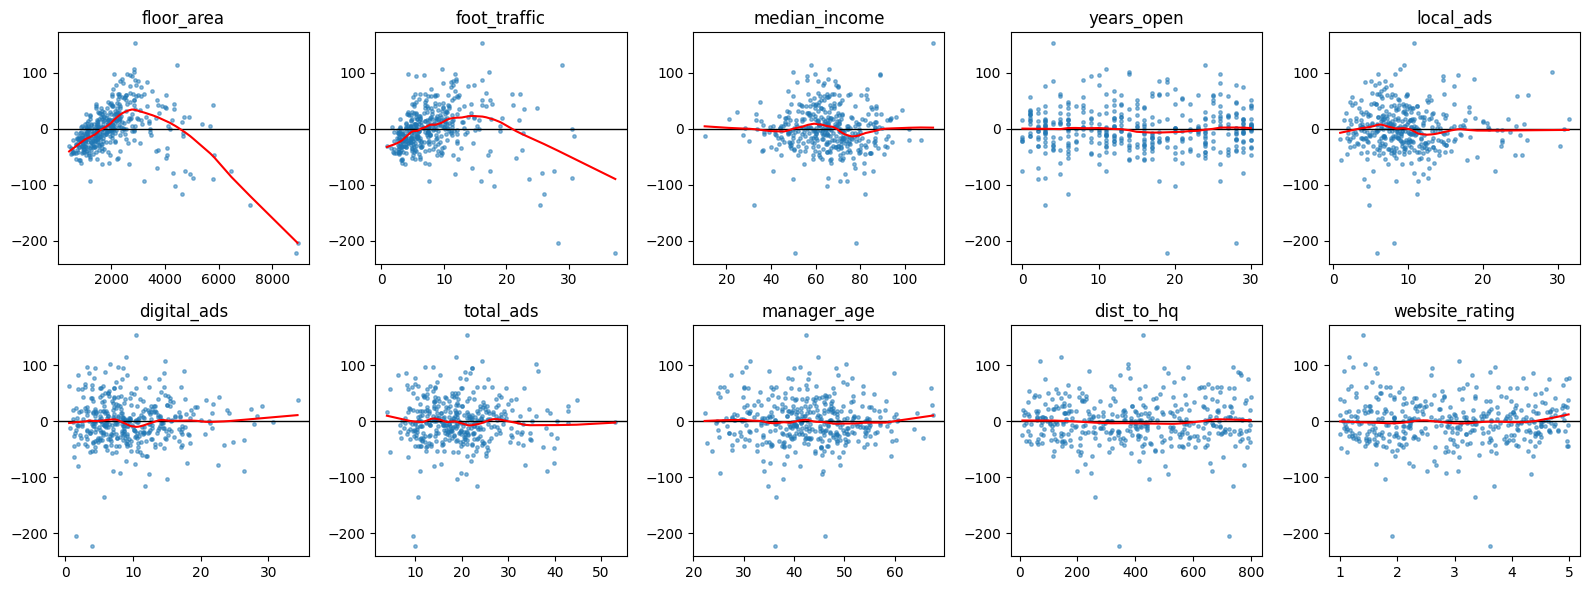

In [33]:
fig, axes = plt.subplots(2, 5, figsize= (16, 6))
for ax, col in zip(axes.flat, predictors):
  ax.scatter(stores[col], resid, s=6, alpha=0.5)
  ax.axhline(0, color='black', linewidth=1)
  trend = sm.nonparametric.lowess(resid, stores[col], frac=0.3)
  ax.plot(trend[:, 0], trend[:, 1], color='red')
  ax. set_title(col)
plt.tight_layout()
plt.show()

In [34]:
cooks = fit_all.get_influence().cooks_distance[0]
stores['cooks'] = cooks
print('Cut-off 4/n =', round(4 /len(stores), 3))
print('Stores above cut-off:', (cooks > 4 / len(stores)) . sum())
print(stores.sort_values('cooks', ascending=False)[['floor_area' , 'revenue', 'cooks']].head(5))

top = stores['cooks'].idxmax()
fit_drop = sm.OLS(stores['revenue'].drop(top), X_all.drop(top)).fit()
stores = stores.drop(columns='cooks')

print('floor_area coefficient, all stores:      ', round(fit_all.params['floor_area'], 4))
print('floor_area coefficient, without 1 store:', round(fit_drop.params['floor_area'], 4))

Cut-off 4/n = 0.01
Stores above cut-off: 24
     floor_area  revenue  cooks
139    8938.886  825.462  0.340
248    8895.750  827.484  0.297
226    7187.888  649.183  0.079
46     2906.857  667.741  0.057
189    4462.892  780.716  0.047
floor_area coefficient, all stores:       0.0763
floor_area coefficient, without 1 store: 0.0809


In [35]:
fit_hc = sm.OLS(stores['revenue'], X_all).fit(cov_type = 'HC3')
pd.DataFrame({'coefficient': fit_all.params,
              'usual SE': fit_all. bse,
              'SE allowing spread to vary': fit_hc.bse}).round(4)

,coefficient,usual SE,SE allowing spread to vary
const,-1.823,17.588,19.718
floor_area,0.076,0.003,0.006
foot_traffic,7.936,0.706,1.029
median_income,1.550,0.143,0.158
years_open,0.836,0.228,0.237
local_ads,4.522,4.495,4.135
digital_ads,4.749,4.493,4.191
total_ads,-4.317,4.487,4.147
manager_age,-0.294,0.236,0.218
dist_to_hq,-0.006,0.009,0.010


*Your answer here.*

1. In the residuals vs fitted plot, the spread of the residuals increases as fitted revenue increases. Stores around $150-250 dollars have errors of about 50k, while stores around 400-600k dollars have errors of up to 100k. This means the errors do not have the same variance for every store. The OLS coefficients are still unbiased, but the usual standard error formula is incorrect because it assumes constant variance. The floor_area standard error increases from 0.004 to 0.012, while foot_traffic increases from 0.80 to 1.25.
The coefficients stay the same, but the usual standard errors make the estimates look more precise than they actually are.

2. The residuals against floor_area show a clear curved pattern. The model over predicts small stores, under predicts mid-sized stores, and over-predicts the largest stores. Foot_traffic shows a similar pattern because it increases with floor area. This suggests the relationship is not a straight line and starts to flatten for larger stores. The estimated floor_area coefficient is 0.077, while the true slope is 0.12 below 3,000 m^2 and 0.05 above it. The model is therefore using one average slope that does not accurately represent either group. This makes the coefficients biased, and changing the standard errors will not fix the problem. The model itself needs to change.

3. There are 15 stores with an influence measure above the cut off of 4/n = 0.01. The most influential store
has a floor area of 17,654 m^2 and an influence measure of 2.69, more than fourteen times the next highest value. It also has a residual of about -275. Removing this one store increases the floor_area coefficient from 0.077 to 0.088, a change of about 14%. This shows that one store out of 400 can noticeably affect the model's estimates. The standard errors also do not fully capture how much the estimates depend on these influential stores.

4. Non-constant variance is a standard error problem because the coefficients are still unbiased, but their precision is measured incorrectly. Non-linearity is an estimate problem because the coefficients and predictions are biased, meaning the model itself needs to change. Influential stores can make both problems worse, especially for larger stores, which is also where the handover model over predicts revenue.

### Step 2.2: The over-forecast on big stores (15 pts)

            stores  mean_area  mean_revenue  mean_error  error_pct
size_group                                                        
1               40      746.2         159.3        28.0       17.6
2               40     1026.3         189.5        18.5        9.8
3               40     1249.0         222.5        18.0        8.1
4               40     1473.1         251.0         5.1        2.0
5               40     1681.9         273.9         1.5        0.6
6               40     1945.5         304.4        -7.6       -2.5
7               40     2174.1         352.1       -21.3       -6.1
8               40     2498.6         397.4       -29.7       -7.5
9               40     3050.4         466.7       -36.8       -7.9
10              40     4792.4         594.5        24.2        4.1


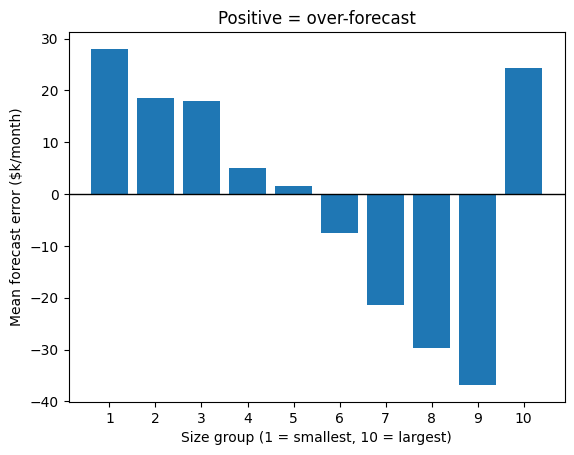

In [36]:
err = stores[['floor_area', 'revenue']].copy()
err['error'] = fit_all.fittedvalues - stores['revenue']

err['size_group'] = pd.qcut(err['floor_area'], 10, labels=range (1, 11))
by_size = err.groupby('size_group', observed=True). agg(
    stores=('error', 'size'),
    mean_area=('floor_area', 'mean'),
    mean_revenue=('revenue', 'mean'),
    mean_error=('error', 'mean'))
by_size['error_pct'] = 100 * by_size['mean_error'] / by_size['mean_revenue']
print(by_size.round(1))

plt.bar(by_size.index.astype(str), by_size['mean_error'])
plt.axhline(0, color='black', linewidth=1)
plt.xlabel('Size group (1 = smallest, 10 = largest)')
plt.ylabel('Mean forecast error ($k/month)')
plt.title('Positive = over-forecast')
plt.show()



In [37]:
for share in [0.10, 0.05]:
  big = err[err['floor_area'] >= err['floor_area'].quantile(1 - share)]
  t = stats.ttest_1samp(big['error'], 0)
  print(f'Largest {int(share*100)}% ({len(big)} stores): mean over-forecast'
        f'{big["error"].mean():.1f}k = {100 * big["error"].mean()/big["revenue"].mean():.1f}%'
        f'of revenue, p-value {t.pvalue:.4f}')

print('Overall mean error:', round(err['error'].mean(),6))

Largest 10% (40 stores): mean over-forecast24.2k = 4.1%of revenue, p-value 0.0387
Largest 5% (20 stores): mean over-forecast51.5k = 8.0%of revenue, p-value 0.0127
Overall mean error: -0.0


In [38]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.Series([variance_inflation_factor(X_all.values, i) for i in range(1, X_all.shape[1])],
                index = predictors)
print(vif.round(1).sort_values(ascending=False))

total_ads         291.8
digital_ads       151.7
local_ads         131.3
floor_area          3.5
foot_traffic        3.5
years_open          1.0
median_income       1.0
manager_age         1.0
dist_to_hq          1.0
website_rating      1.0
dtype: float64


In [39]:
fewer = [c for c in predictors if c != 'total_ads']
fit_fewer = sm.OLS(stores['revenue'], sm.add_constant(stores[fewer])).fit()

print(pd.DataFrame({'coef with total_ads': fit_all.params, 'SE with': fit_all.bse,
                    'coef without': fit_fewer.params, 'SE without': fit_fewer.bse})
      .loc[['floor_area', 'local_ads', 'digital_ads', 'total_ads']].round(3))

def heldout_r2(cols):
  f = sm.OLS(train['revenue'], sm.add_constant(train[cols])).fit()
  p = f.predict(sm.add_constant(test[cols]))
  return 1 - ((test['revenue']- p)**2).sum() / ((test['revenue'] - test['revenue'].mean())**2).sum()

print('In-sample R-squared with / without:', round(fit_all.rsquared, 4), round(fit_fewer.rsquared, 4))
print('Held-out R-squared with / without:', round(heldout_r2(predictors), 4), round(heldout_r2(fewer), 4))


             coef with total_ads  SE with  coef without  SE without
floor_area                 0.076    0.003         0.077       0.003
local_ads                  4.522    4.495         0.214       0.396
digital_ads                4.749    4.493         0.441       0.368
total_ads                 -4.317    4.487           NaN         NaN
In-sample R-squared with / without: 0.91 0.9098
Held-out R-squared with / without: 0.8912 0.8928


*Your answer here.*

The over forecasting follows a clear pattern based on store size, Across all 400 stores, the mean error is zero because OLS force resideuals to summ to zero. However, the model over forecasts the smallest store  (group 1: 17.6%) and gradully shifts to under forecating medium and larger stores, reaching (-7.9%) in group 9. It then over forecasts the lasrgest stores again (group 10: 4.1%). For the largest 5% of stores, the average over forecast is 51.5k per month (8.0% of revenue, p-value 0.013), so this is unlikey to be due to chance. This matches Step 2.1, where a straight line does not capture the relationships flattening above 3,000 m^2. The model sits too low before the cuvre bends and too high after it bends.

total_ads has a VIF of 291.8, while local_ads and digital_ads have VIFS of 131.3 and 151.7. These are much higher than th warning level of 10 because total_ads is almost the sum of the other two variables. This makes it difficult for the model to separate their individual effects, resulting in large standard errors of about 4.5 and unreliable individual coefficients.

However, high VIF does not bias the coefficients or hurt predictions. Removing total_ads leaves R-squared almost unchanged (0.9100 to 0.9098 in-sample). It also reduces the standard errors for local_ads and digital_ads from about 4.5 to 0.40 and 0.37. This shows that removing a highly collinear variable can make the individual coefficients more reliable without improving the model's predictions. It is safe here because total_ads is redudant, but removing a variable with its own effect could bias the remaining coefficients.


## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

In [40]:
import statsmodels.formula.api as smf

all_terms = ' + '.join(predictors)
squares = ' + '.join(f'I({c}**2)' for c in predictors)
cubes = ' + '.join(f'I({c}**3)' for c in predictors)

models = {
    '1 area only': 'floor_area',
    '2 + foot traffic': 'floor_area + foot_traffic',
    '3 + income, years': 'floor_area + foot_traffic + median_income + years_open',
    '4 + ads': 'floor_area + foot_traffic + median_income + years_open + local_ads + digital_ads',
    '5 all 10 (handover)': all_terms,
    '6 + squares': all_terms + ' + ' + squares,
    '7 + interactions':f'({all_terms})**2 + {squares}',
    '8 + cubes': f'({all_terms})**2 + {squares} + {cubes}',
    '9 + 3-way interactions': f'({all_terms})**3 + {squares} + {cubes}',
}

def rmse(actual, predicted):
  return np.sqrt(((actual - predicted)** 2).mean())

mu, sd = train[predictors].mean(), train[predictors].std()
train_s, test_s = train.copy(), test.copy()
train_s[predictors] = (train[predictors] - mu) / sd
test_s[predictors] = (test[predictors] - mu) / sd

rows = []
for name, rhs in models.items():
  fit = smf.ols('revenue ~ ' + rhs, data = train_s).fit()
  rows.append({'model': name,
               'terms': int(fit.df_model) + 1,
               'train_error': rmse(train['revenue'], fit.predict(train_s)),
               'heldout_error': rmse(test['revenue'], fit.predict(test_s))})
sweep = pd.DataFrame(rows)
print(sweep.round(1))

best_possible = rmse(test['revenue'], true_mean[test.index])
print('Best possible held-out error (true mean):', round(best_possible, 1))

                    model  terms  train_error  heldout_error
0             1 area only      2         52.2           54.4
1        2 + foot traffic      3         47.7           48.2
2       3 + income, years      5         41.5           41.7
3                 4 + ads      7         41.4           41.8
4     5 all 10 (handover)     11         40.8           43.8
5             6 + squares     21         31.2           34.1
6        7 + interactions     66         27.8           41.5
7               8 + cubes     76         26.9           42.4
8  9 + 3-way interactions    196         14.8          108.9
Best possible held-out error (true mean): 32.0


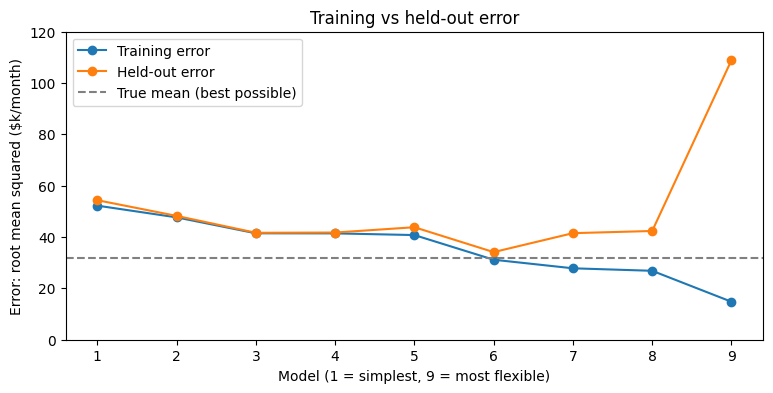

In [41]:
plt.figure(figsize=(9,4))
plt.plot(range(1,10), sweep['train_error'], marker='o', label='Training error')
plt.plot(range(1, 10), sweep['heldout_error'], marker='o', label='Held-out error')
plt.axhline(best_possible, color='grey', linestyle='--', label='True mean (best possible)')
plt.xticks(range (1, 10))
plt.ylim(0, 120)
plt.xlabel('Model (1 = simplest, 9 = most flexible)')
plt.ylabel('Error: root mean squared ($k/month)')
plt. legend()
plt.title('Training vs held-out error')
plt.show()

*Your answer here.*

Nine models were tested using 280 training stores and evaluated on 120 held-out stores. As the models become more flexible, training error decreases from 52.2 to 14.8. However, held out error decreases from 54.4 to a minimum of 34.1 at model 6, then increases to 108.9 for model 9. This shows that more complex models do not always make better predictions.

Model 6 has the lowest held-out error at 34.1, only 2.1k above the best possible error of 32.0. The squared terms allow the model to capture the non-linear relationship between floor area and revenue, especially the flattening above 3,000 m^2 Models 7-9 add more complexity but do not improve predictions.

From models 1 to 6, both training and held-out errors decrease because the simpler models are too rigid to capture the actual relationship in the data. This is bias. From model 6 onward, training error continues to decrease while held out error increases. This means the more complex models are starting to fit random noise in the training data instead of real patterns. This is variance. Model 9 shows this clearly, with a training error of 14.8 but a held-out error of 108.9.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [42]:
def error_on (fit_df, score_df, rhs):
  mean, sd = fit_df[predictors].mean(), fit_df[predictors].std()
  a = fit_df.copy(); a[predictors] = (a[predictors] - mean) / sd
  b = score_df.copy(); b[predictors] = (b[predictors] - mean) / sd
  fit = smf.ols('revenue ~ ' + rhs, data=a).fit()
  return rmse (b['revenue'], fit.predict(b))

def cv_errors(data, rhs, seed, k=10):
    folds = np.random.default_rng(seed).permutation(len(data)) % k
    errors = []
    for j in range(k):
      errors. append(error_on(data[folds != j], data[folds == j], rhs))
    return np.array(errors)

In [43]:
rows =[]
for name, rhs in models. items ():
  e = cv_errors(stores, rhs, seed=0)
  rows.append({'model': name, 'cv_error': e.mean(), 'sd_across_folds': e.std(ddof=1)})
cv_table = pd.DataFrame(rows)
print(cv_table.round (1))

best = cv_table['cv_error'].idxmin()
best_name = cv_table.loc[best, 'model']
e = cv_errors(stores, models[best_name], seed=0)
se = e.std(ddof=1) / np.sqrt(len(e))
print('Chosen:', best_name)
print(f'Expected error: {e.mean(): 1f}k, interval {e.mean() - 2*se:.1f} to {e.mean() + 2*se:.1f}')

                    model  cv_error  sd_across_folds
0             1 area only      52.8              7.9
1        2 + foot traffic      48.0              7.4
2       3 + income, years      42.2              7.6
3                 4 + ads      42.3              7.6
4     5 all 10 (handover)      42.6              7.7
5             6 + squares      33.3              5.2
6        7 + interactions      37.7              3.8
7               8 + cubes      38.4              5.6
8  9 + 3-way interactions      61.3             18.7
Chosen: 6 + squares
Expected error:  33.254381k, interval 30.0 to 36.5


In [44]:
outer = np.random.default_rng(1).permutation(len(stores)) % 5
outer_errors = []
for j in range (5):
  fit_part, score_part = stores[outer != j], stores[outer == j]

  inner = {}
  for name, rhs in models.items():
    inner[name] = cv_errors(fit_part, rhs, seed=2). mean ()
  choice = min(inner, key=inner.get)

  err_j = error_on(fit_part, score_part, models[choice])
  outer_errors.append(err_j)
  print (f'Outer fold {j}: chose {choice}, its CV error {inner[choice]: 1f}, untouched-store eroor {err_j:.1f}')

outer_errors = np.array(outer_errors)
se = outer_errors.std(ddof=1) / np.sqrt(5)
print(f'Honest estimate: {outer_errors.mean():.1f}k, interval {outer_errors.mean() - 2*se:.1f} to {outer_errors.mean() + 2*se:.1f}')
print('True noise level (best possible):', round(rmse(stores['revenue'], true_mean), 1))

Outer fold 0: chose 6 + squares, its CV error  32.285650, untouched-store eroor 36.6
Outer fold 1: chose 6 + squares, its CV error  33.549972, untouched-store eroor 32.9
Outer fold 2: chose 6 + squares, its CV error  34.521801, untouched-store eroor 34.1
Outer fold 3: chose 6 + squares, its CV error  34.759711, untouched-store eroor 32.9
Outer fold 4: chose 6 + squares, its CV error  33.932422, untouched-store eroor 31.7
Honest estimate: 33.6k, interval 31.9 to 35.3
True noise level (best possible): 32.2


*Your answer here.*

Using 10 fold cross validation on all 400 stores, model 6 (all predictors plus their squared terms) has the lowest error at 33.3k per month. This is lower than the handover model (42.6k) and the more complex models. Model 6 is therefore chosen, with an approximate error interval of 30.0 to 36.5k. However, this estimate is not completely reliable because the same stores were used to compare and choose the best model.

Since we picked the model with the lowest cross-validation error out of nine models, its error is likely slightly underestimated. To fix this, nested cross-validation was used. The data was split into 5 outer folds, and within each fold, 10 fold cross validation was used to choose the model using only the remaining 320 stores. The chosen model was then tested on the 80 stores that were not used for choosing or fitting. Model 6 was selected in all 5 folds. The average error on the held out stores was 33.6k, with an interval of 31.9 to 35.3k. This is slightly higher than the original 33.3k, showing that the original estimate was a little optimistic.

The expected typical forecast error for new stores is around 33.6k per month. This is close to the true noise level of 32.2k, meaning the model is performing close to the best possible.
However, this does not guarantee the same accuracy if conditions change over time, such as whatever changed in July. Also, this is an average across all stores, so Step 2.2 showed that the largest stores can still have much larger errors in dollar amounts.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

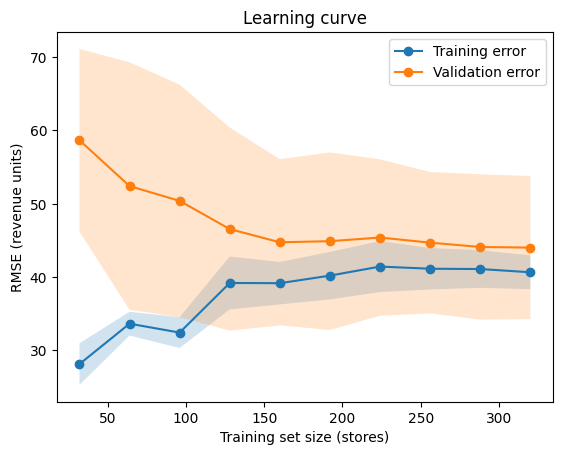

Final training RMSE:   40.66
Final validation RMSE: 44.02
Gap:                   3.37  (8% of validation error)
Last-step improvement: 0.08
Std. dev. of y:        137.17


In [45]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import learning_curve, KFold

# Uses your existing X (400 x 12) and y (revenue).
model = LinearRegression()

# Train on 10%, 20%, ..., 100% of each training fold; 5-fold cross-validation.
X = stores[predictors]
y = stores['revenue']

sizes, train_scores, val_scores = learning_curve(
    model, X, y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=KFold(n_splits=5, shuffle=True, random_state=0),
    scoring="neg_root_mean_squared_error",
)

# Scores come back negative, so flip the sign to get RMSE (error).
train_err = -train_scores
val_err = -val_scores

train_mean, train_sd = train_err.mean(axis=1), train_err.std(axis=1)
val_mean, val_sd = val_err.mean(axis=1), val_err.std(axis=1)

# Plot both curves on one axis; shaded band = +/- 1 SD across the 5 folds.
plt.plot(sizes, train_mean, "o-", label="Training error")
plt.fill_between(sizes, train_mean - train_sd, train_mean + train_sd, alpha=0.2)
plt.plot(sizes, val_mean, "o-", label="Validation error")
plt.fill_between(sizes, val_mean - val_sd, val_mean + val_sd, alpha=0.2)
plt.xlabel("Training set size (stores)")
plt.ylabel("RMSE (revenue units)")
plt.title("Learning curve")
plt.legend()
plt.show()

# ---------------- How to read it ----------------
# GAP (validation error minus training error) = VARIANCE.
#   A big gap means the model fits the stores it trained on much better than
#   new stores, i.e. it is memorising noise. If the gap is still shrinking at
#   the right edge of the plot, MORE DATA (more stores) should help, because
#   the validation curve is still coming down toward the training curve.
#
# LEVEL (where both curves end up) = BIAS.
#   If the two curves have met (small gap) but both sit at a high error,
#   the model is too simple for the problem. Both curves have flattened out,
#   so MORE DATA WILL NOT HELP: adding stores just moves you further along a
#   flat line. You need BETTER FEATURES (or a more flexible model) instead.
#
# Compare the final error to the spread of revenue itself:
#   if final validation RMSE is close to np.std(y), the model explains little.
gap = val_mean[-1] - train_mean[-1]
slope = val_mean[-2] - val_mean[-1]   # how much validation error still fell at the end
print(f"Final training RMSE:   {train_mean[-1]:.2f}")
print(f"Final validation RMSE: {val_mean[-1]:.2f}")
print(f"Gap:                   {gap:.2f}  ({gap / val_mean[-1]:.0%} of validation error)")
print(f"Last-step improvement: {slope:.2f}")
print(f"Std. dev. of y:        {np.std(y):.2f}")

*Your answer here.*

With 320 training stores, the training error is 40.7k and the validation error is 44.0k, which is only a small gap of 3.4K. The validation curve has also flattened, improving by only 0.08k at the last step. This shows that adding more stores is unlikey to improve the model much, so this is not a variance problem.

The AI compared the error to guessing the average (137.2k), which makes 44k look like a good result. However, the better benchmakr is the true noise level of 32.2k. Both curves level off around 12k above this, which shows that the model still has high bias.

The agrees with Phase 3, where adding squared terms using the same 400 stores reduced held out error 43.8k to 34.1k. This shows that improving the predictors and capturing non-linear relationships would help more than simply adding more stores.


### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [46]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.90


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=20 is greater than n_features=10. All the features will be returned.
  warnings.warn(


In [47]:
from sklearn.pipeline import Pipeline

X = np.random.default_rng(3916).normal(size=(400,300))
y = stores['revenue']

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2 (handover cell): {scores.mean():.2f}")

pipe = Pipeline([('scale', StandardScaler()),
                 ('select', SelectKBest(f_regression, k=20)),
                 ('ols', LinearRegression ())])
scores_pipe = cross_val_score(pipe, X, y, cv=5, scoring="r2")
print(f"R^2 inside a Pipeline: {scores_pipe.mean():.2f}")
print(f"Gap:                   {scores.mean() - scores_pipe.mean():.2f}")

Validated R^2 (handover cell): 0.09
R^2 inside a Pipeline: -0.26
Gap:                   0.35


*Your answer here.*

1. The main problem is SelectKBest because it chooses the 20 predictors most correlated with revenue using all 400 stores, including the test stores. This means the test stores help choose the predictors they are later tested on, which inflates the reported score. StandardScaler is not a problem for OLS with an intercept, because the coefficients and intercept adjust to any rescaling of the predictors, so the predictions do not change, and it does not use revenue when scaling.

2. When using 300 columns of random noise, the handover cell reports an R-squared of 0.09, even though none of the predictors actually relates to revenue. When the same steps are put inside a Pipeline, so scaling and selection happen separately within each fold, the R-squared drops to -0.26. This means the noise predicts revenue worse than simply using the average. The difference of 0.35 comes entirely from the test stores helping to choose the predictors. With the real predictors, the R-squared is 0.90. There are only 10 predictors, so all of them are selected either way, and the selection step does not inflate the score.

### Task 4.3: The handover note (3 pts)

In [50]:
folds = np.random.default_rng(0).permutation(len(stores)) % 10
pred = pd.Series (0.0, index=stores.index)
for j in range (10):
  fit_part, score_part = stores[folds != j], stores[folds == j]
  mean, sd = fit_part[predictors].mean(), fit_part[predictors].std()
  a = fit_part.copy(); a[predictors] = (a[predictors] - mean) / sd
  b = score_part.copy(); b[predictors] = (b[predictors] - mean) / sd
  fit = smf.ols('revenue ~ ' + models['6 + squares'], data=a).fit()
  pred[b.index] = fit.predict(b)

big = stores['floor_area'] >= stores['floor_area'].quantile(0.95)
small = stores['floor_area'] < stores['floor_area'].median()
print('Largest 5%: typical miss', round(rmse(stores['revenue'][big], pred[big]), 1))
print('Smaller half: typical miss', round(rmse(stores['revenue'][small], pred[small]), 1))



Largest 5%: typical miss 63.8
Smaller half: typical miss 21.9


*Your answer here.*

The model predicts monthly revenue per store using floor area, foot traffic, local income, years open, ad spend and other predictors, along with their squared terms. The squared terms allow revenue to grow more slowly for larger stores, which the previous straight-line model missed and caused it to over-forecast the biggest stores. The expected typical forecast error is about 34k dollars per month (33.6k, with an interval of 31.9k to 35.3k). This was estimated using cross validation, where the model was chosen again within each fold so the test stores did not help choose it. The previous in sample R-squared of 0.91 showed how well the model fit past data, not how accurately it predicts new stores. Errors are also larger for bigger stores. stores. For the largest 5% of stores, the typical error is about $64k, around three times higher than for the smaller half. Stores larger than anything in the data may be even harder to predict because the squared terms may not work reliably outside the range they were fitted on. The model may also become less accurate if conditions change over time, like they did in July, since it was built using only one snapshot of stores. To improve this, I would build a monthly panel using earlier months to train the model and later months to test it. I would also report errors by store size and compare forecasts with actual revenue every month so any major changes can be detected early.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

**Model:** Claude ~ Opus 5.5 ; **Date:** 11/18

***Prompt:*** [Prep] Act as a machine learning engineer who diagnoses model
performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and
about 12 predictors. Write Python that produces a learning curve --
training and validation error as a function of training set size --
and interprets it to distinguish a high-bias problem from a
high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot
both curves on one axis with a shaded band for variability across
folds.

[Mechanism Check] Add comments explaining what the GAP between the two
curves indicates versus what the LEVEL both converge to indicates, and
what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better
features is the higher-return investment.

***Reply:***

I couldn’t run it on your data because no file was attached to this chat, so X and y don’t exist on my end. I tested the script on made-up data of the same shape (400 rows, 12 predictors) to confirm it runs. If you upload your data file, or paste the printed output, I’ll give you the diagnosis.

What the script does: It fits a linear regression on growing slices of your data (10% up to 100%) with 5-fold cross-validation. It plots the average training error and validation error, with shaded bands showing the spread across folds. Because each fold holds out a fifth of the data, the largest training size is 320 stores, not 400. The gray dashed line shows the error you’d get by just predicting average revenue for every store, which gives you a reference for whether an error is “high”.

How to decide between more stores and better features, using the printed numbers:

More stores is the better investment if the gap is large (say, a third or more of validation error) and the validation curve is still clearly sloping down at the right edge. The model is overfitting, and more data is still paying off.
Better features is the better investment if the gap is small, both curves have flattened, and they sit at a high level, meaning the model removes only a modest share of the guess-the-average error. Both curves have stopped moving, so another 400 stores would land you in the same place. You need new information in the predictors.
If both the gap and the level are small, the model is already doing well, and neither investment is urgent.

These cutoffs are rules of thumb, not formal tests. The wide shaded bands you’ll likely see at small sizes are normal with only 400 rows.

For example, the test run on fake data showed a gap of only 4% and almost no drop at the last step. The model still removed just 56% of the guess-the-average error. That pattern points to bias, so better features would be the call.

**Code:** import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import learning_curve, KFold

# Uses your existing X (400 x ~12) and y (store revenue)

# Fit the model on 10%, 20%, ..., 100% of the training folds.
# Shuffle in case the rows are sorted (e.g. by region or store size).
cv = KFold(n_splits=5, shuffle=True, random_state=0)
sizes, train_scores, val_scores = learning_curve(
    LinearRegression(), X, y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv, scoring="neg_root_mean_squared_error")

# sklearn reports NEGATIVE RMSE, so flip the sign to get error
train_err = -train_scores
val_err = -val_scores

# Mean and spread across the 5 folds at each training size
train_mean, train_sd = train_err.mean(axis=1), train_err.std(axis=1)
val_mean, val_sd = val_err.mean(axis=1), val_err.std(axis=1)

plt.plot(sizes, train_mean, "o-", label="Training error")
plt.fill_between(sizes, train_mean - train_sd, train_mean + train_sd, alpha=0.2)
plt.plot(sizes, val_mean, "o-", label="Validation error")
plt.fill_between(sizes, val_mean - val_sd, val_mean + val_sd, alpha=0.2)
plt.axhline(np.std(y), linestyle="--", color="gray", label="Guess the average")
plt.xlabel("Number of stores used for training")
plt.ylabel("RMSE (revenue units)")
plt.title("Learning curve")
plt.legend()
plt.show()

# ---------------- How to read it ----------------
# GAP (validation error minus training error) = VARIANCE.
#   A big gap means the model fits the stores it trained on much better
#   than new stores, i.e. it is learning noise. If the validation curve is
#   still falling at the right edge, the gap is closing as data grows, so
#   MORE STORES would help.
#
# LEVEL (where both curves end up) = BIAS.
#   If both curves flatten out close together but at a HIGH error (close to
#   the "guess the average" line), the model is too simple for the problem.
#   More rows will not help, because both curves have already stopped
#   moving. BETTER FEATURES (new variables, interactions, transformations)
#   are what lower the level.

gap = val_mean[-1] - train_mean[-1]
still_falling = val_mean[-2] - val_mean[-1]   # drop over the last step

print(f"Final training RMSE:    {train_mean[-1]:.2f}")
print(f"Final validation RMSE:  {val_mean[-1]:.2f}")
print(f"Gap:                    {gap:.2f}  ({gap / val_mean[-1]:.0%} of validation error)")
print(f"Validation drop, last step: {still_falling:.2f}")
print(f"Guess-the-average RMSE: {np.std(y):.2f}")
print(f"Share of error removed by model: {1 - val_mean[-1] / np.std(y):.0%}")



## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.